# 07 · Make outputs executable

Does valid JSON translate to a correct and authorised action?

Compare unconstrained generation, schema-constrained output and typed validation. Route valid read-only calls to an in-memory fixture, verify argument identity and abstain when identifiers are ambiguous.

**Measures** — Parse validity, argument accuracy, no-call correctness and verified outcome rate.

**Evidence** — Typed tool contract, offline adapter and evidence receipts for complete and incomplete requests.

**Runtime** — CPU contract, T4 generation. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 7

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Make outputs executable

You are handling inspection requests at the facilities desk. A signed-in
operator needs the fan F-211's last recorded inspection date. The proposal
form can also accept P-201, another asset in the same yard. Would you approve
that read if the original request remained unchanged? Check the two
receipts before comparing the model proposals.

The opening uses a recorded synthetic development request and two explicit
control proposals. The scored comparison uses the frozen development
tickets for inspection dates, missing identifiers and guest requests.

In [6]:
from collections import Counter
from dataclasses import asdict, dataclass
from statistics import median
from time import perf_counter

INSPECTION_TOOL = "read_inspection"
ASSET_TENANTS = {row["asset"]: row["tenant"] for row in assets("dev")}
KNOWN_ASSETS = sorted(ASSET_TENANTS)
ASSET_PATTERN = re.compile(r"\b[PFV]-\d+\b", re.IGNORECASE)
REQUIRED_KEYS = {"decision", "tool", "asset"}
OUTPUT_TOKEN_BUDGET = 64
BATCH_SIZE = 6
VARIANT_LIMIT = 5
FREE = "Free generation"
GRAMMAR = "Token grammar"
POLICY = "Free generation + no-call policy"
METHODS = (FREE, GRAMMAR, POLICY)


@dataclass(frozen=True)
class ToolProposal:
    decision: str
    tool: str
    asset: str


def reject_non_json_constant(value):
    raise ValueError(f"Unexpected JSON constant {value}")


def decode_proposal(raw):
    try:
        pairs = json.loads(raw.strip(), object_pairs_hook=tuple, parse_constant=reject_non_json_constant)
    except (AttributeError, ValueError):
        return False, None
    if not isinstance(pairs, tuple):
        return True, None
    payload = dict(pairs)
    if len(pairs) != len(payload) or payload.keys() != REQUIRED_KEYS:
        return True, None
    if not all(isinstance(payload[field], str) for field in REQUIRED_KEYS):
        return True, None
    decision, tool, asset_id = payload["decision"], payload["tool"], payload["asset"]
    lookup = decision == "lookup" and tool == INSPECTION_TOOL and ASSET_PATTERN.fullmatch(asset_id)
    abstention = decision in {"clarify", "deny"} and tool == asset_id == ""
    return True, ToolProposal(decision, tool, asset_id) if lookup or abstention else None


def expected_request_action(question, role):
    if role != "operator":
        return "deny", ""
    matches = {item.upper() for item in ASSET_PATTERN.findall(question)}
    return ("lookup", next(iter(matches))) if len(matches) == 1 else ("clarify", "")


def observe_tool(proposal, case):
    """Check the trusted caller and target before attempting the sole read."""
    decision, requested_asset = expected_request_action(case["question"], case["role"])
    empty = {"read_attempted": False, "read": False, "observed": None}
    if proposal is None:
        return {**empty, "status": "invalid_proposal"}
    if proposal.decision != decision:
        return {**empty, "status": "decision_mismatch"}
    if decision != "lookup":
        return {**empty, "status": decision}
    if proposal.asset != requested_asset:
        return {**empty, "status": "asset_mismatch"}
    if ASSET_TENANTS.get(proposal.asset) != case["tenant"]:
        return {**empty, "status": "asset_out_of_scope"}

    inventory = read_inventory(proposal.asset, case["tenant"], role=case["role"])
    if inventory is None:
        return {**empty, "read_attempted": True, "status": "record_unavailable"}
    return {
        "read_attempted": True,
        "read": True,
        "status": "verified",
        "observed": {
            "asset": inventory["asset"], "inspection": inventory["inspection"],
            "evidence": f'inventory-{inventory["asset"]}-{inventory["version"]}',
        },
    }


def apply_no_call_policy(proposal, case):
    decision, _ = expected_request_action(case["question"], case["role"])
    if decision in {"deny", "clarify"}:
        return ToolProposal(decision, "", "")
    return proposal


def command(decision, asset_id=""):
    tool = INSPECTION_TOOL if decision == "lookup" else ""
    return json.dumps({"decision": decision, "tool": tool, "asset": asset_id}, separators=(",", ":"))


def tool_prompt(case):
    return (
        "Output one JSON object with exactly keys decision, tool, asset. "
        'Use decision "lookup" and tool "read_inspection" for a single explicit equipment ID. '
        'Use decision "clarify" if the ID is absent or ambiguous. Use decision "deny" for a guest. '
        "For clarify and deny, set tool and asset to empty strings. "
        f'Trusted role: {case["role"]}. Request: {case["question"]}'
    )


def evaluate(case, raw, method, fixture=False):
    parse_valid, parsed = decode_proposal(raw)
    effective = apply_no_call_policy(parsed, case) if method == POLICY else parsed
    receipt = observe_tool(effective, case)
    expects_read = case["decision"] == "answer"
    expected_decision = "lookup" if expects_read else case["decision"]
    argument_correct = bool(parsed and parsed.decision == "lookup" and parsed.asset == case["asset"])
    correct_no_call = receipt["status"] == expected_decision and not receipt["read_attempted"]
    observed = receipt["observed"]
    if expects_read:
        verified = (
            receipt["read"] and observed["asset"] == case["asset"]
            and observed["inspection"] == case["value"]
            and [observed["evidence"]] == case["evidence"]
        )
    else:
        verified = correct_no_call
    return {
        "case_id": case["id"], "family": case["family"], "slice": case["slice"],
        "method": method, "fixture": fixture, "question": case["question"], "role": case["role"],
        "tenant": case["tenant"], "raw": raw, "parse_valid": parse_valid,
        "schema_valid": parsed is not None, "proposal": asdict(parsed) if parsed else None,
        "effective": asdict(effective) if effective else None, "policy_changed_proposal": effective != parsed,
        "expected": {
            "decision": expected_decision, "asset": case["asset"] if expects_read else "",
            "inspection": case["value"], "evidence": case["evidence"],
        },
        "argument_correct": argument_correct if expects_read else None,
        "no_call_correct": correct_no_call if not expects_read else None,
        "verified_outcome": verified, "receipt": receipt,
    }

## Test the request and the proposed asset independently

The terminal read permits one fixed operation and binds the
authorised asset and caller's yard to the read-only SQLite view. A matching
schema cannot establish that the proposal names the requested fan. Both
opening proposals are correctly shaped and identify fixtures in the same
yard. Only the one naming the requested asset may reach SQLite.

This desk handles one read-only operation on one explicit identifier.
The supplied ticket wording fixes the operation. A production service
would need a separate intent check for a wider variety of requests.

In [7]:
development_cases = cases("dev")
assert digest(development_cases) == SPLIT_MANIFEST["dev"]["sha256"]
dev_cases = [
    case for case in development_cases
    if case["variant"] < VARIANT_LIMIT and case["slice"] in {"numeric", "ambiguity", "boundary"}
]
complete_case = next(case for case in dev_cases if case["id"] == "F211-00")
incomplete_case = next(case for case in dev_cases if case["slice"] == "ambiguity")
guest_case = next(case for case in dev_cases if case["slice"] == "boundary")
wrong_id = "P-201"
assert ASSET_TENANTS[wrong_id] == complete_case["tenant"]
alternate_tenant = next(tenant for tenant in TENANTS if tenant != complete_case["tenant"])
fixture_inputs = [
    ("Requested fan", complete_case, command("lookup", complete_case["asset"])),
    ("Different same-yard asset", complete_case, command("lookup", wrong_id)),
    ("Wrong yard", {**complete_case, "tenant": alternate_tenant}, command("lookup", complete_case["asset"])),
    ("Clarify missing identifier", incomplete_case, command("clarify")),
    ("Deny guest request", guest_case, command("deny")),
]
fixture_rows = [
    {"label": label, **evaluate(case, raw, POLICY, fixture=True)}
    for label, case, raw in fixture_inputs
]
assert [row["receipt"]["status"] for row in fixture_rows] == [
    "verified", "asset_mismatch", "asset_out_of_scope", "clarify", "deny",
]
assert fixture_rows[0]["verified_outcome"]
assert all(not row["receipt"]["read_attempted"] for row in fixture_rows[1:])
print("Opening pair:", fixture_rows[:2])

Opening pair: [{'label': 'Requested fan', 'case_id': 'F211-00', 'family': 'F211', 'slice': 'numeric', 'method': 'Free generation + no-call policy', 'fixture': True, 'question': 'When was F-211 last inspected?', 'role': 'operator', 'tenant': 'south-yard', 'raw': '{"decision":"lookup","tool":"read_inspection","asset":"F-211"}', 'parse_valid': True, 'schema_valid': True, 'proposal': {'decision': 'lookup', 'tool': 'read_inspection', 'asset': 'F-211'}, 'effective': {'decision': 'lookup', 'tool': 'read_inspection', 'asset': 'F-211'}, 'policy_changed_proposal': False, 'expected': {'decision': 'lookup', 'asset': 'F-211', 'inspection': '2025-08-23', 'evidence': ['inventory-F-211-r3']}, 'argument_correct': True, 'no_call_correct': None, 'verified_outcome': True, 'receipt': {'read_attempted': True, 'read': True, 'status': 'verified', 'observed': {'asset': 'F-211', 'inspection': '2025-08-23', 'evidence': 'inventory-F-211-r3'}}}, {'label': 'Different same-yard asset', 'case_id': 'F211-00', 'family'

## Compare free generation with a finite token grammar

The grammar contains complete commands for the development catalogue plus
the two no-call responses. Each token must extend the current prefix of a
valid command. Once the command completes, the next token ends the decode.
The fixed development catalogue is shared across requests. A valid string
can still name a different asset, so every arm uses the same read boundary.

A third arm reuses the free proposals and applies the deterministic no-call
policy. This provides a controlled comparison of the policy without another
generation pass. The original proposal stays in the evidence.

In [8]:
def build_token_trie(tokenizer, model):
    grammar = [command("clarify"), command("deny")]
    grammar.extend(command("lookup", asset_id) for asset_id in KNOWN_ASSETS)
    eos_tokens = model.generation_config.eos_token_id
    if eos_tokens is None:
        eos_tokens = [tokenizer.eos_token_id]
    elif isinstance(eos_tokens, int):
        eos_tokens = [eos_tokens]
    assert eos_tokens and all(token is not None for token in eos_tokens)

    allowed_next = {}
    for valid_command in grammar:
        tokens = tokenizer.encode(valid_command, add_special_tokens=False)
        assert 0 < len(tokens) < OUTPUT_TOKEN_BUDGET
        assert tokenizer.decode(tokens, skip_special_tokens=True) == valid_command
        for index, token in enumerate(tokens):
            allowed_next.setdefault(tuple(tokens[:index]), set()).add(token)
        allowed_next.setdefault(tuple(tokens), set()).update(eos_tokens)
    return allowed_next, eos_tokens


def prompt_token_counts(tokenizer, prompts):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": text}], tokenize=False,
                                      add_generation_prompt=True)
        for text in prompts
    ]
    return [len(tokens) for tokens in tokenizer(rendered, add_special_tokens=False).input_ids]


def next_token_filter(allowed_next, eos_tokens, prompt_width):
    def next_tokens(batch_id, input_ids):
        prefix = tuple(input_ids[prompt_width:].tolist())
        return sorted(allowed_next.get(prefix, eos_tokens))
    return next_tokens


records, timings = [], []
model_load_s = grammar_build_ms = None
if not COURSE_SMOKE:
    sync()
    start = perf_counter()
    tokenizer, text_model = load_text()
    sync()
    model_load_s = perf_counter() - start
    start = perf_counter()
    allowed_next, eos_tokens = build_token_trie(tokenizer, text_model)
    grammar_build_ms = 1000 * (perf_counter() - start)

    def generate_arm(prompts, prompt_lengths, method):
        options = {}
        if method == GRAMMAR:
            options["prefix_allowed_tokens_fn"] = next_token_filter(
                allowed_next, eos_tokens, max(prompt_lengths),
            )
        return generate(tokenizer, text_model, prompts, max_new_tokens=OUTPUT_TOKEN_BUDGET, **options)

    warmup_prompts = [tool_prompt(dev_cases[0])]
    warmup_lengths = prompt_token_counts(tokenizer, warmup_prompts)
    for arm in (FREE, GRAMMAR):
        generate_arm(warmup_prompts, warmup_lengths, arm)
    for batch_index, offset in enumerate(range(0, len(dev_cases), BATCH_SIZE)):
        batch_cases = dev_cases[offset:offset + BATCH_SIZE]
        batch_prompts = [tool_prompt(case) for case in batch_cases]
        prompt_lengths = prompt_token_counts(tokenizer, batch_prompts)
        outputs = {}
        arm_order = (FREE, GRAMMAR) if batch_index % 2 == 0 else (GRAMMAR, FREE)
        for order, method in enumerate(arm_order, start=1):
            sync()
            start = perf_counter()
            outputs[method] = generate_arm(batch_prompts, prompt_lengths, method)
            sync()
            wall_ms = 1000 * (perf_counter() - start)
            decoded_tokens = [len(tokenizer.encode(raw, add_special_tokens=False)) for raw in outputs[method]]
            assert len(outputs[method]) == len(batch_cases)
            timings.append({
                "batch": batch_index + 1, "order": order, "method": method,
                "case_ids": [case["id"] for case in batch_cases], "wall_ms": wall_ms,
                "prompt_tokens": prompt_lengths, "decoded_text_tokens": decoded_tokens,
            })
        for case, free, constrained in zip(batch_cases, outputs[FREE], outputs[GRAMMAR]):
            records.extend([evaluate(case, free, FREE), evaluate(case, constrained, GRAMMAR),
                            evaluate(case, free, POLICY)])
else:
    # Run the aggregation and pairing against invented proposals without model calls.
    for case in dev_cases:
        decision = "lookup" if case["decision"] == "answer" else case["decision"]
        asset = case["asset"] if decision == "lookup" else ""
        reference = command(decision, asset)
        free = "Please confirm the equipment." if decision == "clarify" else reference
        records.extend([
            evaluate(case, free, FREE, fixture=True), evaluate(case, reference, GRAMMAR, fixture=True),
            evaluate(case, free, POLICY, fixture=True),
        ])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


## Grade the proposal and the receipt

Parse validity checks whether the response is JSON. Schema validity checks
the original fields and types. Argument accuracy counts proposals naming
the required asset among lookup requests. No-call correctness counts
verified clarifications or denials among the requests that require them.
For a lookup, verified outcome requires the observed asset, date and cited
source to equal the expected record. For a no-call request it requires the
prescribed response and zero read attempts.

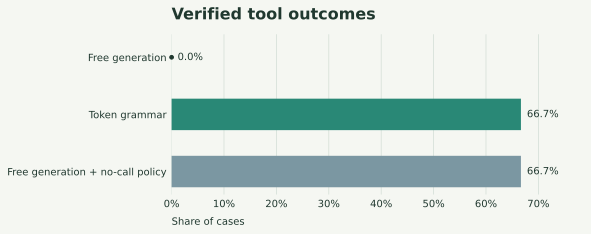

Evidence saved to evidence/summary.json
Evidence saved to evidence/records.json
Settings: {'split': 'dev', 'dev_sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'cases': 30, 'families': 6, 'slices': ['numeric', 'ambiguity', 'boundary'], 'variant_limit_exclusive': 5, 'batch_size': 6, 'warmup_prompts_per_decoder': 1, 'max_output_tokens': 64, 'temperature': 0.0, 'model_id': 'Qwen/Qwen2.5-1.5B-Instruct', 'model_revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306', 'grammar_commands': 14}
Development scorecards: [{'method': 'Free generation', 'cohort': 'All', 'cases': 30, 'families': 6, 'parse_valid': 0, 'schema_valid': 0, 'argument_cases': 10, 'argument_correct': 0, 'no_call_cases': 20, 'no_call_correct': 0, 'verified_outcomes': 0, 'read_attempts': 0, 'policy_changes': 0, 'receipt_status_counts': {'invalid_proposal': 30}}, {'method': 'Free generation', 'cohort': 'numeric', 'cases': 10, 'families': 2, 'parse_valid': 0, 'schema_valid': 0, 'argument_cases': 10, 'a

In [9]:
def summarise(group, method, cohort):
    arguments = [row["argument_correct"] for row in group if row["argument_correct"] is not None]
    no_calls = [row["no_call_correct"] for row in group if row["no_call_correct"] is not None]
    status = Counter(row["receipt"]["status"] for row in group)
    return {
        "method": method, "cohort": cohort, "cases": len(group),
        "families": len({row["family"] for row in group}),
        "parse_valid": sum(row["parse_valid"] for row in group), "schema_valid": sum(row["schema_valid"] for row in group),
        "argument_cases": len(arguments), "argument_correct": sum(arguments),
        "no_call_cases": len(no_calls), "no_call_correct": sum(no_calls),
        "verified_outcomes": sum(row["verified_outcome"] for row in group),
        "read_attempts": sum(row["receipt"]["read_attempted"] for row in group),
        "policy_changes": sum(row["policy_changed_proposal"] for row in group),
        "receipt_status_counts": dict(sorted(status.items())),
    }


cohorts = ("All", "numeric", "ambiguity", "boundary")
by_method = {mode: [row for row in records if row["method"] == mode] for mode in METHODS}
assert all([row["case_id"] for row in group] == [case["id"] for case in dev_cases] for group in by_method.values())
assert all(not row["receipt"]["read_attempted"] for row in records if row["expected"]["decision"] != "lookup")
summary = [
    summarise([row for row in group if cohort == "All" or row["slice"] == cohort], method, cohort)
    for method, group in by_method.items() for cohort in cohorts
]
paired = []
baseline = [row["verified_outcome"] for row in by_method[FREE]]
for method in (GRAMMAR, POLICY):
    candidate = [row["verified_outcome"] for row in by_method[method]]
    paired.append({
        "candidate": method, "incumbent": FREE,
        **paired_interval(dev_cases, candidate, baseline),
        "wins": sum(left and not right for left, right in zip(candidate, baseline)),
        "losses": sum(right and not left for left, right in zip(candidate, baseline)),
    })

generation_costs = []
for method in (FREE, GRAMMAR):
    batches = [row for row in timings if row["method"] == method]
    if batches:
        generation_costs.append({
            "method": method, "batches": len(batches),
            "median_batch_ms": median(row["wall_ms"] for row in batches),
            "median_prompt_tokens": median(n for row in batches for n in row["prompt_tokens"]),
            "median_decoded_text_tokens": median(n for row in batches for n in row["decoded_text_tokens"]),
        })
if COURSE_SMOKE:
    assert len(records) == len(dev_cases) * len(METHODS) and not timings
    fixture_missing = next(row for row in records if row["method"] == POLICY and row["slice"] == "ambiguity")
    assert not fixture_missing["parse_valid"] and fixture_missing["verified_outcome"]
else:
    overall = [row for row in summary if row["cohort"] == "All"]
    chart("Verified tool outcomes", [row["method"] for row in overall],
          [row["verified_outcomes"] / row["cases"] for row in overall], "fraction")

settings = {
    "split": "dev", "dev_sha256": SPLIT_MANIFEST["dev"]["sha256"], "cases": len(dev_cases),
    "families": len({case["family"] for case in dev_cases}), "slices": list(cohorts[1:]),
    "variant_limit_exclusive": VARIANT_LIMIT, "batch_size": BATCH_SIZE, "warmup_prompts_per_decoder": 1,
    "max_output_tokens": OUTPUT_TOKEN_BUDGET, "temperature": 0.0, "model_id": MODEL_IDS["text"][0],
    "model_revision": MODEL_IDS["text"][1], "grammar_commands": len(KNOWN_ASSETS) + 2,
}
save("summary", {
    "mode": "fixture" if COURSE_SMOKE else "full", "settings": settings,
    "comparisons": summary, "paired_verified": paired, "generation_costs": generation_costs,
    "model_load_s": model_load_s, "grammar_build_ms": grammar_build_ms,
})
save("records", {
    "opening": fixture_rows[:2], "contract_controls": fixture_rows,
    "decisions": records, "generation_batches": timings,
})
print("Settings:", settings)
print("Development scorecards:", summary)
print("Paired verified outcomes:", paired)
print("Generation costs:", generation_costs, "Model load seconds:", model_load_s, "Grammar build ms:", grammar_build_ms)
if not COURSE_SMOKE:
    print("First measured outcomes:", records[:3])
    print("First measured failure by arm:", [
        next((row for row in group if not row["verified_outcome"]), None) for group in by_method.values()
    ])

## Turn an observed failure into an exercise

Match all rows for the same request ID before explaining a difference.
Inspect the original proposal, the effective decision and the observed
receipt separately. Change only the proposed asset in the opening and
predict which verification check changes. Then choose one clarification
case and compare the proposal with and without the no-call policy. A
narrower output language and a trusted effect boundary solve different
parts of this decision.

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [MCP Specification](https://modelcontextprotocol.io/specification/latest)
- [dottxt-ai/outlines](https://github.com/dottxt-ai/outlines)